# Fig. 6: PPO and CEM operating conditions and yield on the evaluation batches.

- (a) PPO, start of intervention x decision interval: mean yield on 100 validation batches, 3 training seeds (a1rF_obs16_s{s}_dw{d}_ts*_yield.npy).
- (b) CEM, same grid, narrow amplitude, 100 validation batches (cem_fine_b2a_s{s}_d{d}_narrow_s*.npz).
- (c) Amplitude: PPO on the validation batches (wide amplitude diverged during training, so the policy stays at its initial no-intervention yield; hatched cell) and CEM on 50 paired low-yield batches (cem_fine_canon.npz, cem_fine_wide80_s*.npz).
- (d) PPO with a lower-PAA-bound penalty: yield on 100 validation batches, seeds 0-2 (dot = seed, horizontal line = seed mean).
- (e) Yield on the 200 evaluation batches (dot + batch-bootstrap 95 % interval, as in Fig. 4c): no intervention, APC, estimated PAA + BO (per-batch mean over 10 runs), PPO (per-batch mean over 10 seeds) and CEM (10 h start, 12 h interval, wide amplitude).
Outlined cells = conditions carried to the evaluation batches (PPO 10 h / 6 h, CEM 10 h / 12 h).
- (a) and (b) use colour scales of equal kg span. Style: 17 x 11 cm, DejaVu Sans, 5.5 pt.

In [1]:
import sys; sys.path.insert(0, '..')          # repository root, for paths.py
from paths import DATA, OUTD                   # data/ and output/

In [2]:
import glob, numpy as np, matplotlib; matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
G = DATA; OUT = OUTD + 'fig6'
INK, GRY = '#23201a', '#8f897d'
C_BASE, C_APC, C_BO, C_PPO, C_CEM = GRY, '#8a3324', '#2a7f7a', '#c9a227', '#1f4e79'
plt.rcParams.update({'font.family': ['DejaVu Sans'], 'font.size': 5.5, 'axes.titlesize': 6.5, 'axes.labelsize': 5.5,
                     'xtick.labelsize': 5.0, 'ytick.labelsize': 5.0, 'axes.linewidth': 0.5, 'xtick.major.width': 0.5,
                     'ytick.major.width': 0.5, 'xtick.major.size': 2, 'ytick.major.size': 2, 'mathtext.default': 'regular'})
bank = np.load(G + 'dev_bank_200a.npz'); SEEDS = [int(s) for s in bank['seeds']]; BASE = float(np.mean(bank['ybase']))
STARTS, INTS, DW = (10, 80), (6, 12, 24), {6: 30, 12: 60, 24: 120}
CHOSEN = {'PPO': (10, 6), 'CEM': (10, 12)}
def ppo(s, d):
    A = np.array([np.load(f)[:100] for f in sorted(glob.glob(G + f'a1rF_obs16_s{s}_dw{DW[d]}_ts*_yield.npy'))]); assert len(A) == 3
    return float(np.nanmean(np.nanmean(A, 0)))
def cem(s, d):
    got = {}
    for f in sorted(glob.glob(G + f'cem_fine_b2a_s{s}_d{d}_narrow_s*.npz')):
        z = np.load(f, allow_pickle=True)
        for sd, y in zip(z['seeds'], z['fine_yield']):
            if y is not None and np.isfinite(float(y)): got[int(sd)] = float(y)
    return float(np.mean([got[sd] for sd in SEEDS if sd in got]))
M = {'PPO': np.array([[ppo(s, d) for d in INTS] for s in STARTS]), 'CEM': np.array([[cem(s, d) for d in INTS] for s in STARTS])}
SPAN = max(np.ptp(v) for v in M.values()) * 1.15
def cem_amp():
    def load(f):
        z = np.load(G + f, allow_pickle=True); return {int(a): float(y) for a, y in zip(z['seeds'], z['fine_yield']) if y is not None and np.isfinite(float(y))}
    W = {}; [W.update(load(f)) for f in ('cem_fine_wide80_s0.npz', 'cem_fine_wide80_s1.npz')]; N = load('cem_fine_canon.npz'); S = sorted(set(W) & set(N))
    return np.mean([N[k] for k in S]), np.mean([W[k] for k in S]), len(S)
def style(a):
    for sp in ('top', 'right'): a.spines[sp].set_visible(False)
    for sp in ('left', 'bottom'): a.spines[sp].set_color(INK)
    a.tick_params(colors=INK)
def title(a, s): a.set_title(s, loc='left', fontweight='bold', color=INK, pad=4)
def lum(c): return 0.299 * c[0] + 0.587 * c[1] + 0.114 * c[2]
fig = plt.figure(figsize=(17 / 2.54, 11 / 2.54), facecolor='white')
gs = GridSpec(2, 6, figure=fig, height_ratios=[1, 1], wspace=1.2, hspace=0.62, left=0.07, right=0.97, top=0.94, bottom=0.14)   # top: (a)(b)(c); bottom: (d) penalty, (e) yield
gsa = [gs[0, 0:2], gs[0, 2:4]]; gsb = [gs[0, 4:6], gs[1, 3:6]]; gsd = gs[1, 0:3]

In [3]:
# (a)(b) condition grids
for k, (name, col) in enumerate((('PPO', C_PPO), ('CEM', C_CEM))):
    ax = fig.add_subplot(gsa[k]); v = M[name]; lo = v.min() - (SPAN - np.ptp(v)) / 2
    cmap = LinearSegmentedColormap.from_list(name, ['#ffffff', col]); im = ax.imshow(v, cmap=cmap, vmin=lo - SPAN * .35, vmax=lo + SPAN, aspect='auto')
    for i in range(2):
        for j in range(3):
            tc = 'white' if lum(im.cmap(im.norm(v[i, j]))) < .53 else INK
            ax.text(j, i - .10, f'{v[i, j]:,.0f}', ha='center', va='center', fontsize=6.0, color=tc, fontweight='bold')
            ax.text(j, i + .22, f'{v[i, j] - BASE:+,.0f}', ha='center', va='center', fontsize=5.0, color=tc)
            if CHOSEN[name] == (STARTS[i], INTS[j]): ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, fill=False, ec=INK, lw=1.2, zorder=5))
    ax.set_xticks(range(3)); ax.set_xticklabels([f'{d} h' for d in INTS], color=INK); ax.set_yticks(range(2)); ax.set_yticklabels([f'{s} h' for s in STARTS], color=INK)
    ax.set_xlabel('Interval between decisions', color=INK); ax.set_ylabel('Start of intervention', color=INK)
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.tick_params(length=0); title(ax, f'({"ab"[k]}) {name}')

In [4]:
# (c) Amplitude
ax = fig.add_subplot(gsb[0]); cn, cw, ncem = cem_amp()
VALS = {'PPO': (M['PPO'][0, 0], BASE), 'CEM': (cn, cw)}; CHO = {'PPO': 0, 'CEM': 1}
for i, (name, col) in enumerate((('PPO', C_PPO), ('CEM', C_CEM))):
    a_, b_ = VALS[name]
    for j, val in enumerate((a_, b_)):
        if name == 'PPO' and j == 1:
            ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, fc='white', ec=GRY, hatch='//////', lw=0.4)); tc = INK
        else:
            fc = plt.matplotlib.colors.to_rgba(col, 0.25 + 0.6 * (j == CHO[name] or (name == 'PPO')))
            ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, fc=fc, lw=0)); tc = 'white' if lum(fc) < .53 and fc[3] > .6 else INK
        ax.text(j, i, f'{val:,.0f}', ha='center', va='center', fontsize=6.0, color=tc, fontweight='bold', zorder=6,
                bbox=dict(fc='white', ec='none', pad=0.6) if (name == 'PPO' and j == 1) else None)
        if CHO[name] == j: ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, fill=False, ec=INK, lw=1.2, zorder=5))
ax.set_xlim(-.5, 1.5); ax.set_ylim(1.5, -.5); ax.set_xticks([0, 1]); ax.set_xticklabels(['Narrow', 'Wide'], color=INK)
ax.set_yticks([0, 1]); ax.set_yticklabels(['PPO', 'CEM'], color=INK); ax.set_xlabel('Amplitude', color=INK)
for sp in ax.spines.values(): sp.set_visible(False)
ax.tick_params(length=0); title(ax, '(c)')

In [5]:
# (e) Yield on the evaluation batches, same layout as Fig. 4c
tb = np.load(G + 'testset_fig5_REPORTONLY_random200.npz'); S5 = [int(s) for s in tb['seeds']]
got = {}
for f in sorted(glob.glob(G + 'cem_fine_w45_wide_b5_s10d12_s*.npz')):
    z = np.load(f, allow_pickle=True)
    for sd, y in zip(z['seeds'], z['fine_yield']):
        if y is not None and np.isfinite(float(y)): got[int(sd)] = float(y)
YL = [('No\nintervention', tb['ybase'].astype(float), C_BASE),
      ('APC', np.load(G + 'apc_streamA_b5_v2.npz', allow_pickle=True)['y_apcA'].astype(float), C_APC),
      ('BO-tuned\ncontroller', np.mean([np.load(G + f'fin_boctrl_patch_s{s}_rand200_yield.npy') for s in range(10)], 0), C_BO),
      ('PPO', np.nanmean([np.load(G + f'fin_faith_obs16_rand200_ts{s}_yield.npy') for s in range(10)], 0), C_PPO),
      ('CEM', np.array([got.get(s, np.nan) for s in S5]), C_CEM)]
ad = fig.add_subplot(gsb[1]); style(ad); rb = np.random.default_rng(0)
for x, (nm, y, c) in enumerate(YL):
    y = y[np.isfinite(y)]; bs = y[rb.integers(0, len(y), (5000, len(y)))].mean(1); lo, hi = np.percentile(bs, [2.5, 97.5])
    ad.errorbar(x, y.mean(), yerr=[[y.mean() - lo], [hi - y.mean()]], fmt='o', ms=3.4, mfc=c, mec=c, ecolor=c, elinewidth=0.9, capsize=0)
ad.set_xticks(range(len(YL))); ad.set_xticklabels([n for n, _, _ in YL], color=INK); ad.tick_params(axis='x', length=0)
ad.set_xlim(-0.5, len(YL) - 0.5); ad.set_ylim(2600, 4300); ad.set_ylabel('Penicillin yield (kg)', color=INK); title(ad, '(e)')

In [6]:
# (d) Lower-PAA-bound penalty (final training environment): 100 validation batches, seeds 0-2. Dot = seed, line = seed mean
PEN = [('None', None), ('300\n40', (300, 40)), ('400\n10', (400, 10)), ('400\n40', (400, 40)), ('400\n160', (400, 160)), ('600\n40', (600, 40))]
def pen(c):
    f = (lambda t: G + f'b2a_faith_obs16_ts{t}_yield.npy') if c is None else (lambda t: G + f'b2a_pen_lo{c[0]}_l{c[1]}_ts{t}_yield.npy')
    return np.array([np.nanmean(np.load(f(t))[:100]) for t in range(3)])
PV = [pen(c) for _, c in PEN]
ap = fig.add_subplot(gsd); style(ap)
ap.axhline(PV[0].mean(), color=GRY, lw=0.5, ls=(0, (3, 2.2)), zorder=1)
for x, v in enumerate(PV):
    ap.scatter(x + np.array([-.12, 0, .12]), v, s=7, color=C_PPO, lw=0, zorder=3)
    ap.plot([x - .24, x + .24], [v.mean()] * 2, color=INK, lw=0.9, zorder=4)
ap.set_xticks(range(len(PEN))); ap.set_xticklabels([n for n, _ in PEN], color=INK); ap.tick_params(axis='x', length=0)
ap.set_xlim(-0.6, len(PEN) - 0.4); ap.set_ylim(3000, 3800); ap.set_ylabel('Penicillin yield (kg)', color=INK)
ap.set_xlabel('Lower PAA bound (mg L$^{-1}$) and penalty weight $\\lambda$', color=INK); title(ap, '(d)')
_tl = ap.get_xticklabels()[1]                                                       # row labels for the two-line ticks (top = bound, bottom = λ), using the tick-label transform and line spacing
ap.text(-0.62, _tl.get_position()[1], 'Bound\nλ', transform=_tl.get_transform(), ha='right', va='top', color=INK,
        fontsize=_tl.get_fontsize(), multialignment='right')
for ext, kw in (('png', dict(dpi=600)), ('pdf', {})):
    fig.savefig(f'{OUT}.{ext}', facecolor='white', **kw)
print('saved', OUT); print('penalty', [(n.replace(chr(10), '·'), v.round().tolist(), round(v.mean())) for (n, _), v in zip(PEN, PV)]); print('PPO', M['PPO'].round()); print('CEM', M['CEM'].round()); print('amplitude CEM', round(cn), round(cw), ncem, '· no intervention', BASE)
Y = {n.replace('\n', ' '): y for n, y, _ in YL}
for n, y in Y.items(): print(f'  {n:22s} {np.nanmean(y):6.0f}')
for a_, b_ in (('PPO', 'APC'), ('PPO', 'BO-tuned controller'), ('CEM', 'PPO'), ('CEM', 'APC')):
    d = Y[a_] - Y[b_]; d = d[np.isfinite(d)]; bs = d[rb.integers(0, len(d), (5000, len(d)))].mean(1)
    print(f'  {a_} − {b_}: {d.mean():+.0f} [{np.percentile(bs, 2.5):+.0f}, {np.percentile(bs, 97.5):+.0f}]')

saved ../output/fig6
penalty [('None', [3735.0, 3662.0, 3698.0], 3698), ('300·40', [3691.0, 3678.0, 3724.0], 3698), ('400·10', [3676.0, 3730.0, 3594.0], 3667), ('400·40', [3720.0, 3640.0, 3738.0], 3700), ('400·160', [3576.0, 3104.0, 3158.0], 3279), ('600·40', [3336.0, 3429.0, 3640.0], 3468)]
PPO [[3698. 3682. 3603.]
 [3712. 3674. 3527.]]
CEM [[3932. 3932. 3927.]
 [3910. 3915. 3913.]]
amplitude CEM 3715 3907 50 · no intervention 2754.9872907554627
  No intervention          2800
  APC                      3467
  BO-tuned controller      3650
  PPO                      3708
  CEM                      4114
  PPO − APC: +241 [+196, +283]
  PPO − BO-tuned controller: +58 [+27, +85]
  CEM − PPO: +406 [+365, +451]
  CEM − APC: +647 [+604, +691]


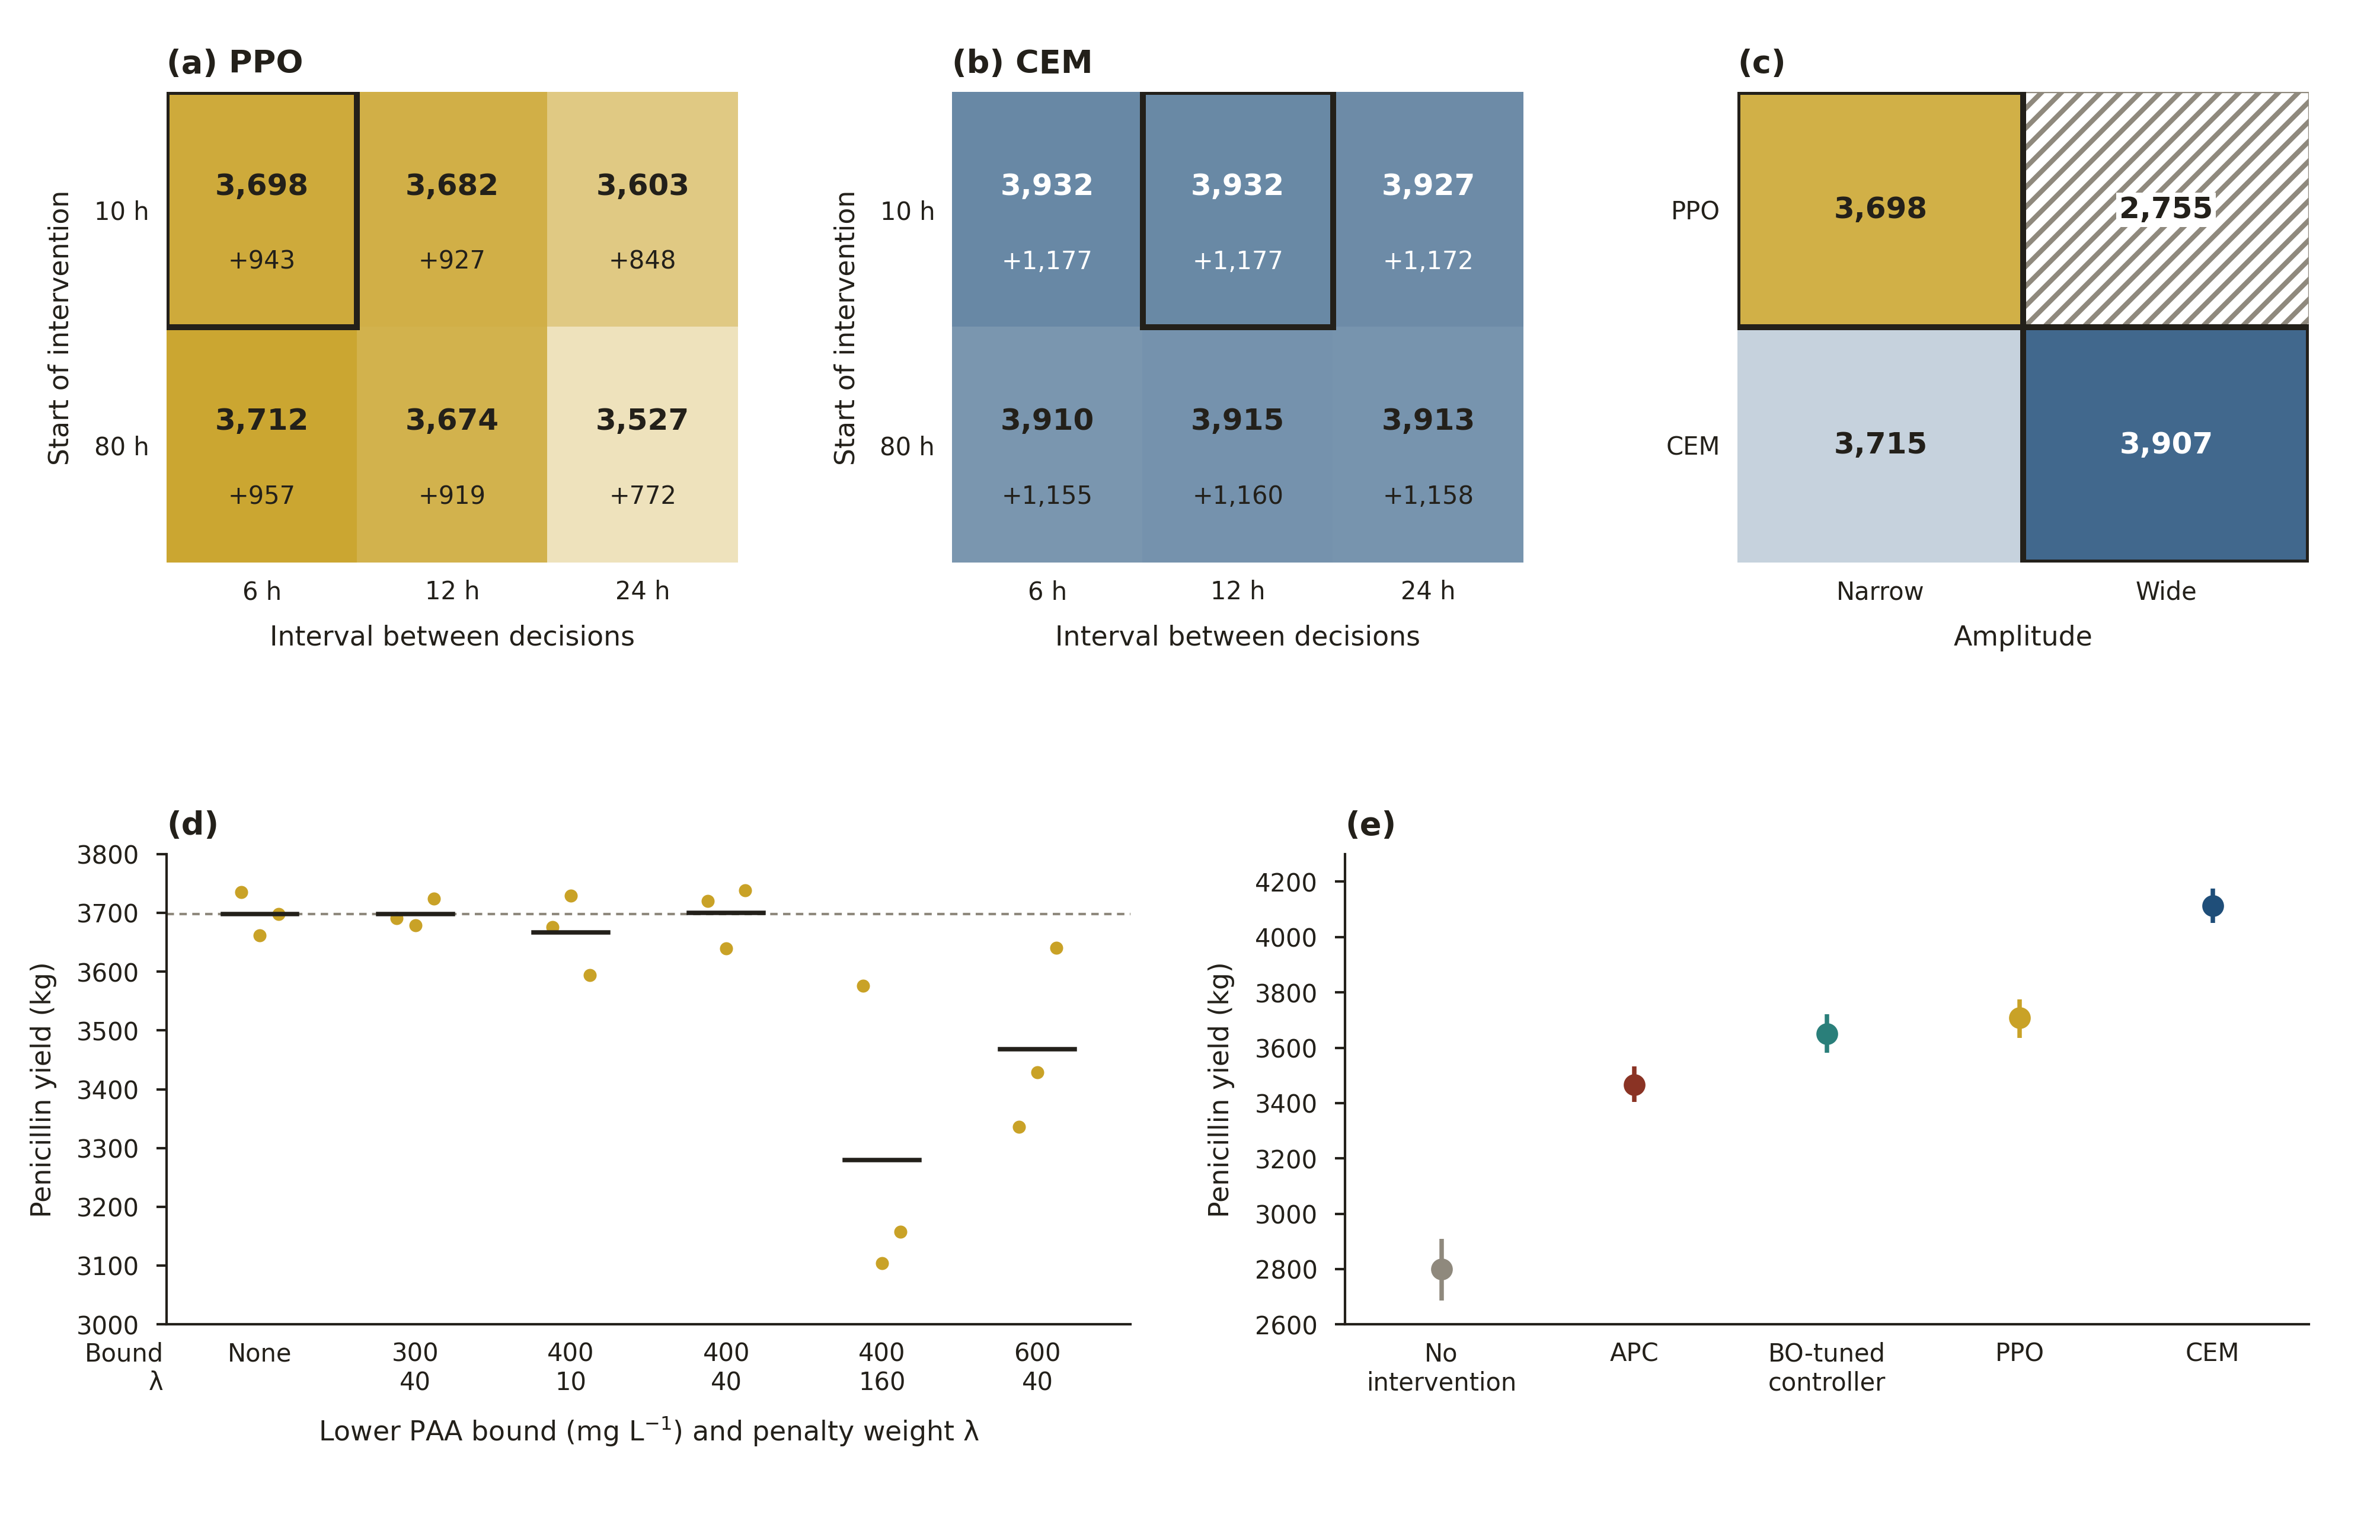

In [7]:
from IPython.display import Image
Image(OUTD + 'fig6.png', width=900)